## Лабораторна робота № 5 ##

**Тема:** Вступ до TensorFlow і побудова простої нейронної мережі для регресії.

**Варіант:** 10

**Мета роботи:** Навчитися створювати та обробляти тензори TensorFlow, будувати й навчати нейронну мережу для регресії, порівнювати моделі за валідаційною помилкою та зберігати навчену модель.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.5.3


## Тензори ##

In [3]:
# Створення константного тензора
a = tf.constant([[1., 2.], [3., 4.]], dtype=tf.float32)

# Створення тензора b
b = tf.constant([10., 20.], dtype=tf.float32)

# Створення змінної та зміна її значень
w = tf.Variable([0.2, 0.5], dtype=tf.float32)
w.assign([0.3, 0.6])

# Перевірка властивостей тензора
print("Shape:", a.shape)
print("Dtype:", a.dtype)
print("Rank:", tf.rank(a).numpy())

# Поелементні операції та broadcasting
print("a + b:\n", (a + b).numpy())

print("a * a:\n", (a * a).numpy())

# Матричне множення
print("a @ a:\n", tf.matmul(a, a).numpy())

print("Змінна w:", w.numpy())

Shape: (2, 2)
Dtype: <dtype: 'float32'>
Rank: 2
a + b:
 [[11. 22.]
 [13. 24.]]
a * a:
 [[ 1.  4.]
 [ 9. 16.]]
a @ a:
 [[ 7. 10.]
 [15. 22.]]
Змінна w: [0.3 0.6]


## Дані та поділ ##

train (420, 1) float32
validation (90, 1) float32
test (90, 1) float32


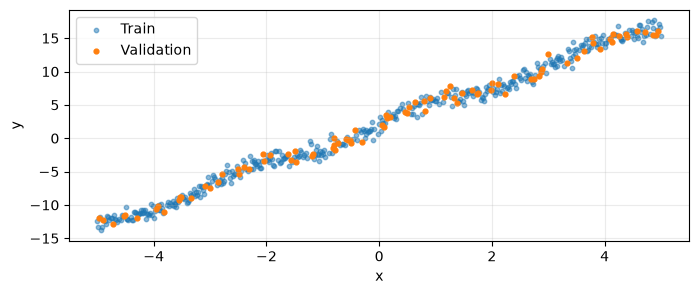

In [4]:
SEED = 42

keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

# Генерація вхідних значень
x = np.linspace(-5, 5, 600, dtype=np.float32)

# Додавання випадкового шуму
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)

# Формування нелінійної залежності
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

# Перетворення на двовимірні масиви
x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

# Перемішування даних
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

# Поділ на train, validation і test
x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

# Перевірка розмірів і типів даних
for name, values in [
    ("train", x_train),
    ("validation", x_val),
    ("test", x_test)
]:
    print(name, values.shape, values.dtype)

# Побудова графіка тренувальних і валідаційних даних
plt.figure(figsize=(8, 3))

plt.scatter(
    x_train[:, 0], y_train[:, 0],
    s=10, alpha=0.5, label="Train"
)

plt.scatter(
    x_val[:, 0], y_val[:, 0],
    s=12, label="Validation"
)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Створення та навчання базової моделі ##

In [7]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

# Створення моделі
model = build_model()

# Налаштування процесу навчання
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

# Навчання базової моделі протягом 100 епох
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0,
)

print("Найменший val_loss:", min(history.history["val_loss"]))
    

Найменший val_loss: 0.5787851810455322


## Порівняння з EarlyStopping - варіант 10 ##

In [8]:
# Створення нової моделі з тією самою архітектурою
model_es = build_model()

model_es.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

# Дострокове завершення навчання
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Навчання максимум 300 епох
history_es = model_es.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

print("Епох базової моделі:", len(history.history["loss"]))
print("Епох моделі з EarlyStopping:", len(history_es.history["loss"]))

print("Найменший val_loss базової моделі:",min(history.history["val_loss"]))

print( "Найменший val_loss з EarlyStopping:",min(history_es.history["val_loss"]))

Епох базової моделі: 100
Епох моделі з EarlyStopping: 33
Найменший val_loss базової моделі: 0.5787851810455322
Найменший val_loss з EarlyStopping: 0.6795901656150818


## Графіки навчання ##

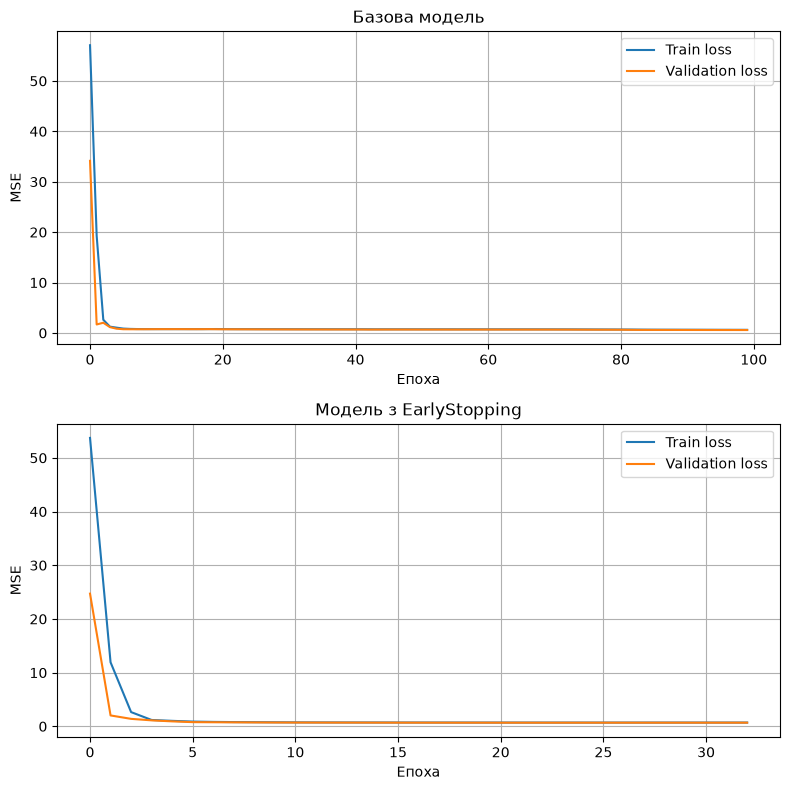

In [12]:

# Графіки навчання обох моделей
plt.figure(figsize=(8, 8))

# Базова модель
plt.subplot(2, 1, 1)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Базова модель")
plt.legend()
plt.grid(True)

# Модель з EarlyStopping
plt.subplot(2, 1, 2)
plt.plot(history_es.history["loss"], label="Train loss")
plt.plot(history_es.history["val_loss"], label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Модель з EarlyStopping")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()




## Оцінювання моделей на test ##

In [13]:

baseline_val_loss = min(history.history["val_loss"])
early_val_loss = min(history_es.history["val_loss"])

if early_val_loss < baseline_val_loss:
    best_model = model_es
    best_model_name = "EarlyStopping"
else:
    best_model = model
    best_model_name = "Baseline"

print("Обрана модель:", best_model_name)

print("Baseline test:")
print(model.evaluate(
    x_test, y_test, return_dict=True, verbose=0
))

print("EarlyStopping test:")
print(model_es.evaluate(
    x_test, y_test, return_dict=True, verbose=0
))


Обрана модель: Baseline
Baseline test:
{'loss': 0.5774054527282715, 'mae': 0.5990567803382874}
EarlyStopping test:
{'loss': 0.6498384475708008, 'mae': 0.6240465641021729}


## Прогнозування, збереження та перевірка моделі ##

In [17]:
# Дані для прогнозування
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)
# Прогнозування базової моделі
pred_baseline = model.predict(x_new, verbose=0)

# Прогнозування моделі з EarlyStopping
pred_es = model_es.predict(x_new, verbose=0)

print("Прогнози базової моделі:")
print(pred_baseline)

print("\nПрогнози моделі з EarlyStopping:")
print(pred_es)

# Вибираємо найкращу модель за val_loss
if min(history_es.history["val_loss"]) < min(history.history["val_loss"]):
    best_model = model_es
    print("\nОбрано модель з EarlyStopping")
else:
    best_model = model
    print("\nОбрано базову модель")

# Зберігаємо обрану модель
best_model.save("lab5_model.keras")

# Завантажуємо збережену модель
restored = keras.models.load_model("lab5_model.keras")

# Перевіряємо прогнози після завантаження
pred_original = best_model.predict(x_new, verbose=0)
pred_restored = restored.predict(x_new, verbose=0)

np.testing.assert_allclose(
    pred_original,
    pred_restored,
    rtol=1e-5
)

print("\nМодель успішно збережена та завантажена!")
print("Прогнози завантаженої моделі:")
print(pred_restored)


Прогнози базової моделі:
[[-10.529826]
 [  1.764175]
 [ 13.744332]]

Прогнози моделі з EarlyStopping:
[[-10.558257 ]
 [  1.9974151]
 [ 14.061593 ]]

Обрано базову модель

Модель успішно збережена та завантажена!
Прогнози завантаженої моделі:
[[-10.529826]
 [  1.764175]
 [ 13.744332]]
